In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path().resolve().parents[0]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
    
    

from src.config import PROCESSED_DATA_DIR
from src.utils.plots import save_figure, style_plot, create_figure, add_bar_labels, add_source, YOUTUBE_RED, save_table, interpret_eta_squared, DARK_RED,interpret_test
import pandas as pd

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/source-distribution.png


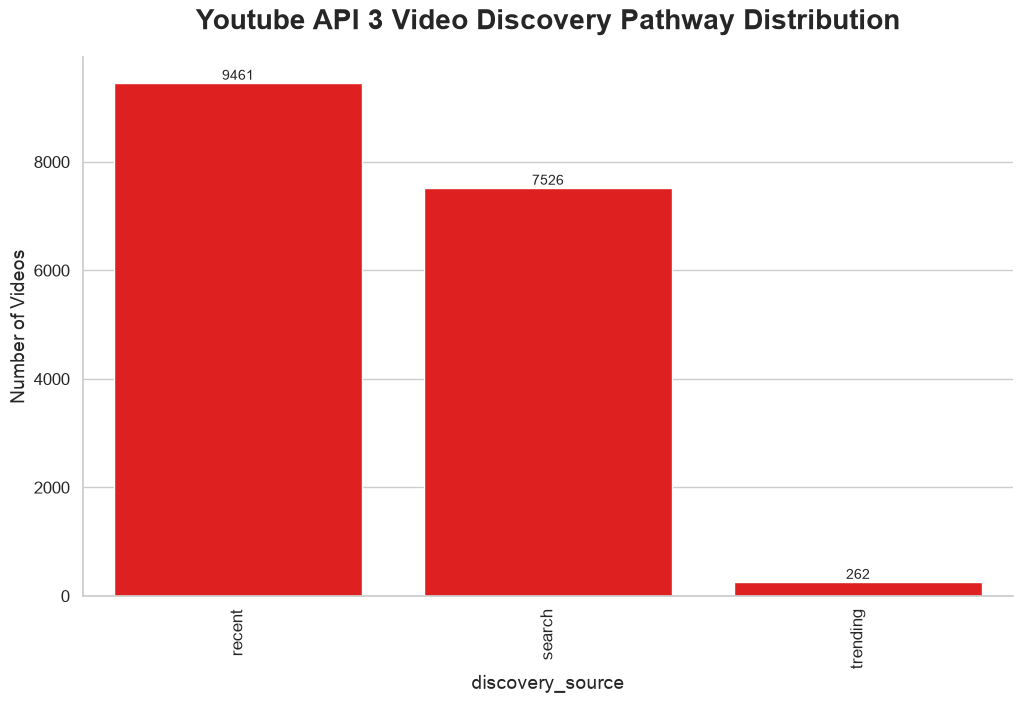

,video_id,title,description,published_at,category_id,tags,duration,channel_id,channel_title,views,...,hour,day_of_week,duration_seconds,duration_minutes,is_short,duration_group,is_viral,tag_count,has_tags,category_name
0,ELkyDvO-j6Q,treat u right,Provided to YouTube by EMPIRE Distribution\n\n...,2026-07-02 22:11:35+00:00,10,"['FOLA', 'Ayra Starr', 'treat u right']",PT2M58S,UC4mHpkf_26sEWN8M5PMpV_w,FOLA - Topic,120661,...,22,3,178,2.97,0,1-5 mins,0,3,True,Music
1,hMlHf-YXVUM,ALAKADA GEN Z 3 (Official Trailer) | Latest Ni...,ALAKADA GEN Z 3 Official Trailer is here! 🎬😂 \...,2026-07-05 17:00:39+00:00,24,"['Alakada Gen Z 3', 'Alakada Gen Z 3 trailer',...",PT2M33S,UCoSnFVOBlcdgjSUETGd65kA,Toyin Abraham TV,69067,...,17,6,153,2.55,0,1-5 mins,0,23,True,Entertainment
2,BaO6Dnxquv8,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,🔴 GTA 5 LIVE – DON’T BLINK! SECRET MOD ACTIVAT...,2026-07-05 20:06:24+00:00,20,"['gta 5 live', 'gta v live stream', 'gta 5 gam...",PT31M8S,UC9OTne2HnCn_kkyx8NodI-g,Pixel Hunters,14163447,...,20,6,1868,31.13,0,15-60 mins,1,25,True,Gaming
3,KkDHSWq7XGw,Jorja Smith - Alive feat. Wizkid,Jorja Smith - Alive feat. Wizkid - Out now: ht...,2026-07-02 16:00:27+00:00,10,"['jorja smith', 'alive', 'wizkid', 'what are t...",PT3M31S,UCHA6dVPvxRdLQ5Uu-uX3MLw,Jorja Smith,952264,...,16,3,211,3.52,0,1-5 mins,0,5,True,Music
4,DVHPZ36Sav8,IYE Latest Yoruba Movie 2026 l Official Traile...,Some homes don’t let you leave…\nAnd if you do...,2026-06-29 17:00:24+00:00,22,[],PT1M28S,UCi00_82Wh1q_rm2Yz8m7GIA,THE DAMILOLA ONI TV,72623,...,17,0,88,1.47,0,1-5 mins,0,0,False,People & Blogs


<Figure size 640x480 with 0 Axes>

In [2]:
df = pd.read_csv(PROCESSED_DATA_DIR / "youtube_clean.csv")

source_count = (
    df["discovery_source"].value_counts()
    .sort_values(ascending=False)
    )

# video distribution by source
fig, ax = create_figure()
sns.barplot(
    x=source_count.index,
    y=source_count.values,
    ax=ax,
    color=YOUTUBE_RED
)
ax.tick_params(axis="x", rotation=90)

style_plot(ax=ax, xlabel='discovery_source', ylabel='Number of Videos', title="Youtube API 3 Video Discovery Pathway Distribution")
add_bar_labels(ax)
save_figure(fig=fig,  filename='q2/source-distribution.png')
plt.show()
plt.clf()


df.head()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/disproportionate-amplification-scatter.png


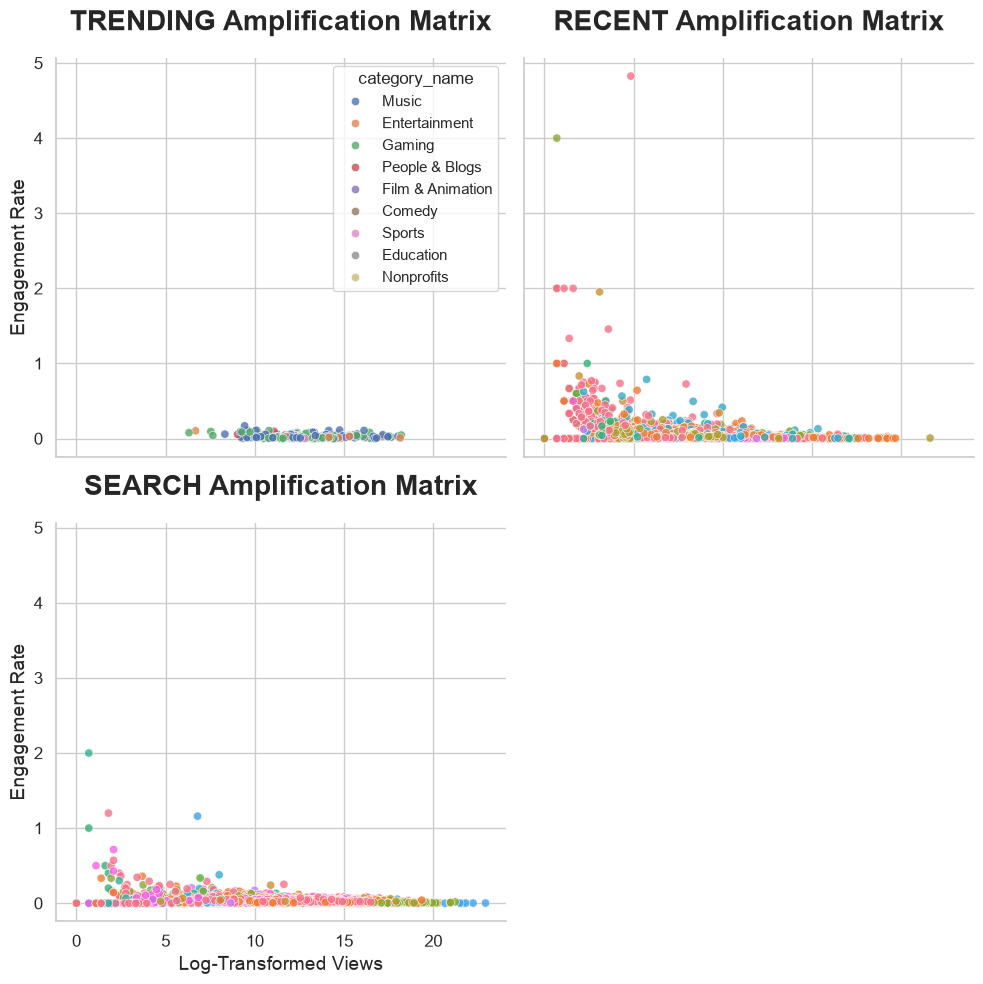

<Figure size 640x480 with 0 Axes>

In [10]:
# Visualizing Disproportionate Amplification: Engagement vs. Scale
fig, axes = plt.subplots(2, 2, figsize=(10, 10), sharey=True, sharex=True)
axes_flat = axes.flatten()

# all distinct pathways
unique_sources = df["discovery_source"].unique()


for i, source in enumerate(unique_sources):
    ax = axes_flat[i]
    source_data = df[df['discovery_source'] == source]
    
    sns.scatterplot(
        data=source_data,
        x='log_views',             
        y='engagement_rate',
        hue='category_name',
        ax=ax,
        alpha=0.8,
        legend=True if i == 0 else False,
       
    )
    
   
    style_plot(
        ax=ax, 
        xlabel='Log-Transformed Views', 
        ylabel='Engagement Rate' if i in [0, 2] else '', 
        title=f"{source.upper()} Amplification Matrix"
    )

# hide unused axis
axes_flat[3].set_visible(False)



plt.tight_layout()
save_figure(fig=fig, filename='q2/disproportionate-amplification-scatter.png')
plt.show()
plt.clf()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/pathway-visibility-bars.png


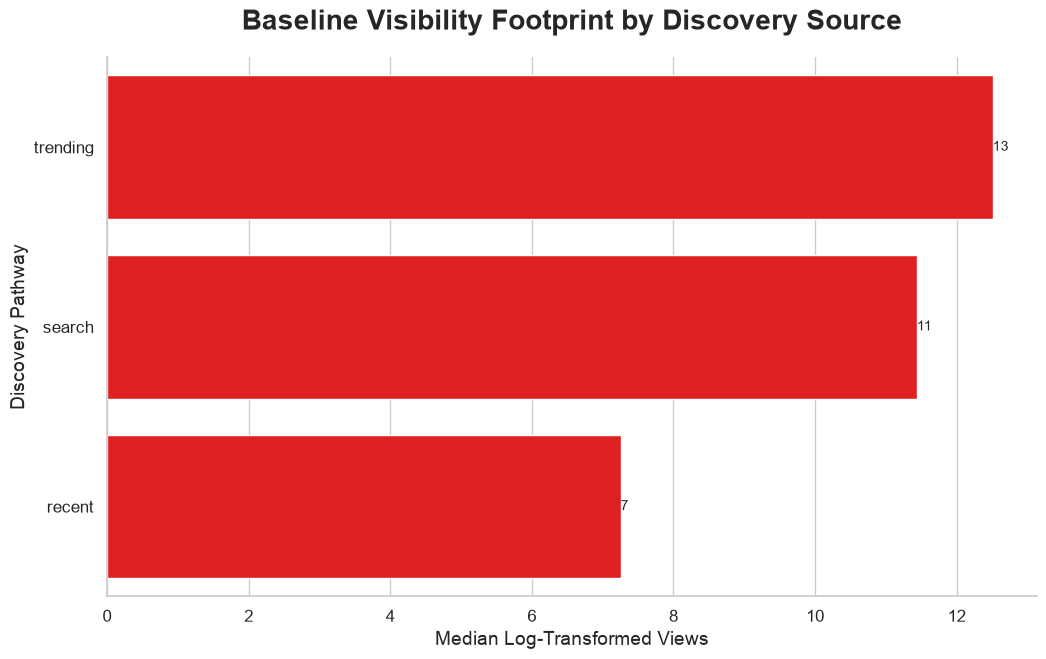

<Figure size 640x480 with 0 Axes>

In [ ]:
# median view per pathway
pathway_visibility = df.groupby('discovery_source')['log_views'].median().sort_values(ascending=False).reset_index()

fig, ax = create_figure()

sns.barplot(
data=pathway_visibility,
x='log_views',
y='discovery_source',
ax=ax,
color=YOUTUBE_RED
)

style_plot(
ax=ax,
xlabel='Median Log-Transformed Views',
ylabel='Discovery Pathway',
title='Baseline Visibility Footprint by Discovery Source'
)

add_bar_labels(ax)

save_figure(fig=fig, filename='q2/pathway-visibility-bars.png')
plt.show()
plt.clf()

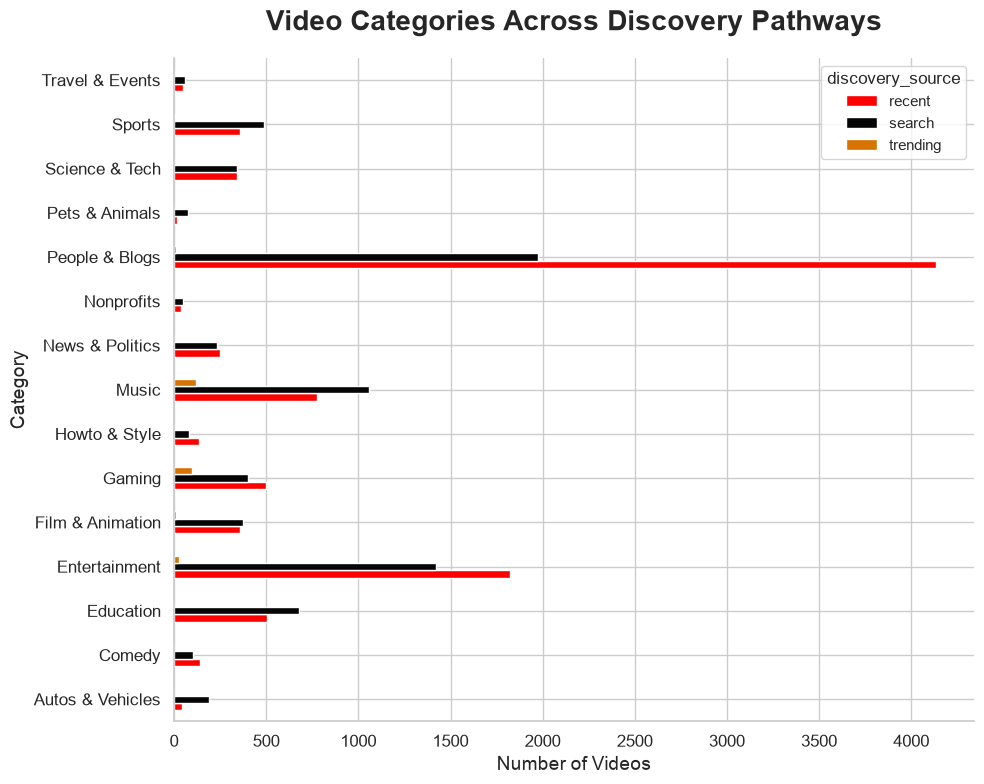

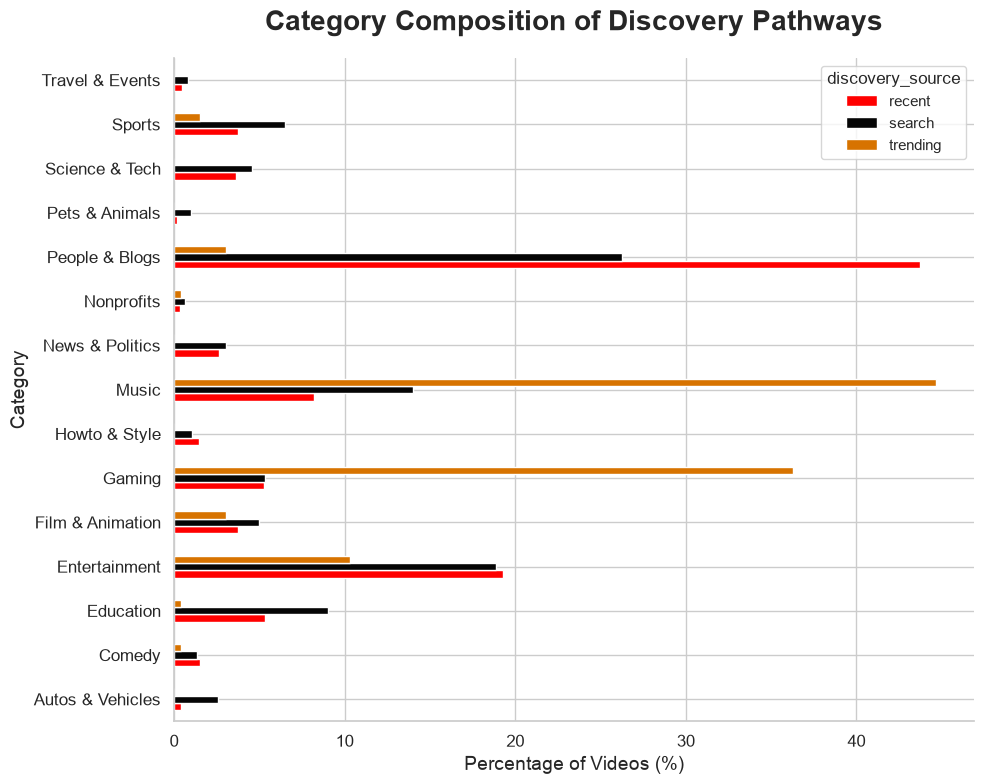

In [42]:
# category distribution accross discovery sources
category_source = (
    df.groupby(
        ["discovery_source", "category_name"]
    )
    .size()
    .reset_index(name="count")
)


#cross tabs
category_table = pd.crosstab(
    df["category_name"],
    df["discovery_source"]
)

# category_table
# category_source

# get percentage by discovery source
category_percent = (
    pd.crosstab(
        df["category_name"],
        df["discovery_source"],
        normalize="columns"
    )
    * 100
)




ig, ax = create_figure(figsize=(10,8))

category_table.plot(
    kind="barh",
    ax=ax,
    color=['#FF0000', "#050505", "#D77300", "#313131"]
    
)

style_plot(
    ax=ax,
    xlabel="Number of Videos",
    ylabel="Category",
    title="Video Categories Across Discovery Pathways"
)

plt.tight_layout()
plt.show()




fig, ax = create_figure(figsize=(10,8))

category_percent.plot(
    kind="barh",
    ax=ax,
    color=['#FF0000', "#050505", "#D77300", "#313131"]
)

style_plot(
    ax=ax,
    xlabel="Percentage of Videos (%)",
    ylabel="Category",
    title="Category Composition of Discovery Pathways"
)

plt.tight_layout()
plt.show()

Saved: /Users/pro2020/projects/python/social-media-algorithm-analysis/outputs/q2/view-dist-across-pathways.png


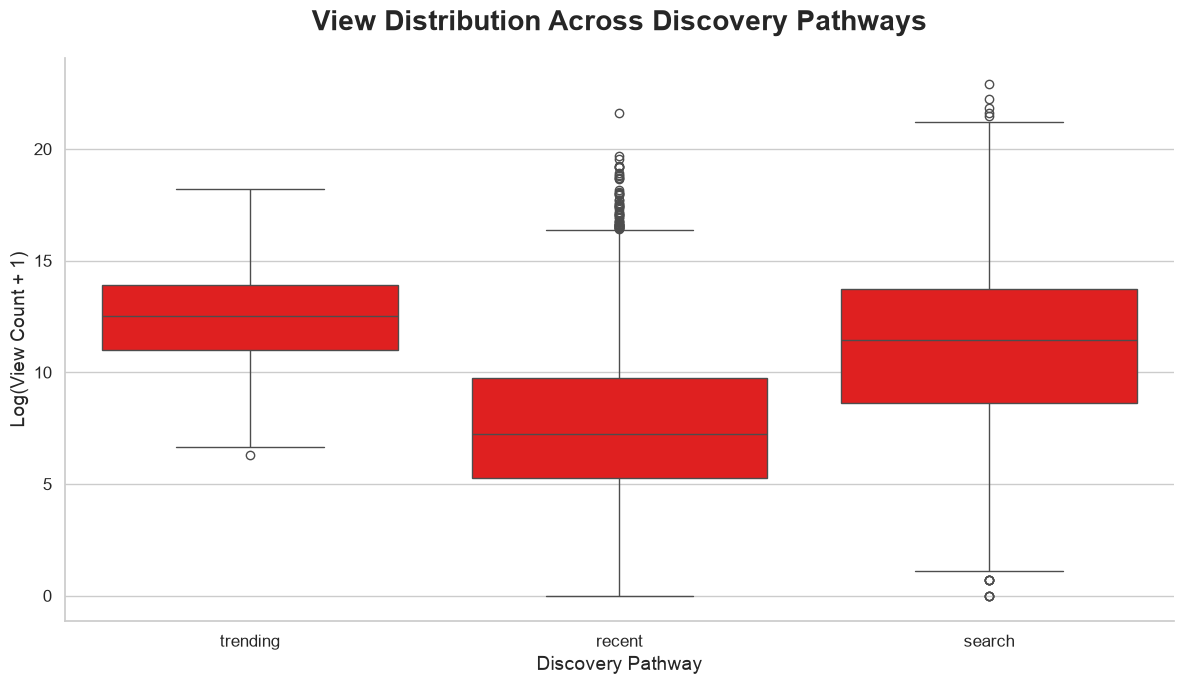

<Figure size 640x480 with 0 Axes>

In [45]:
fig, ax = create_figure()

sns.boxplot(
    data=df,
    x="discovery_source",
    y="log_views",
    ax=ax,
    color=YOUTUBE_RED
)

style_plot(
    ax=ax,
    xlabel="Discovery Pathway",
    ylabel="Log(View Count + 1)",
    title="View Distribution Across Discovery Pathways"
)



save_figure(fig=fig, filename='q2/view-dist-across-pathways.png')
plt.tight_layout()
plt.show()
plt.clf()

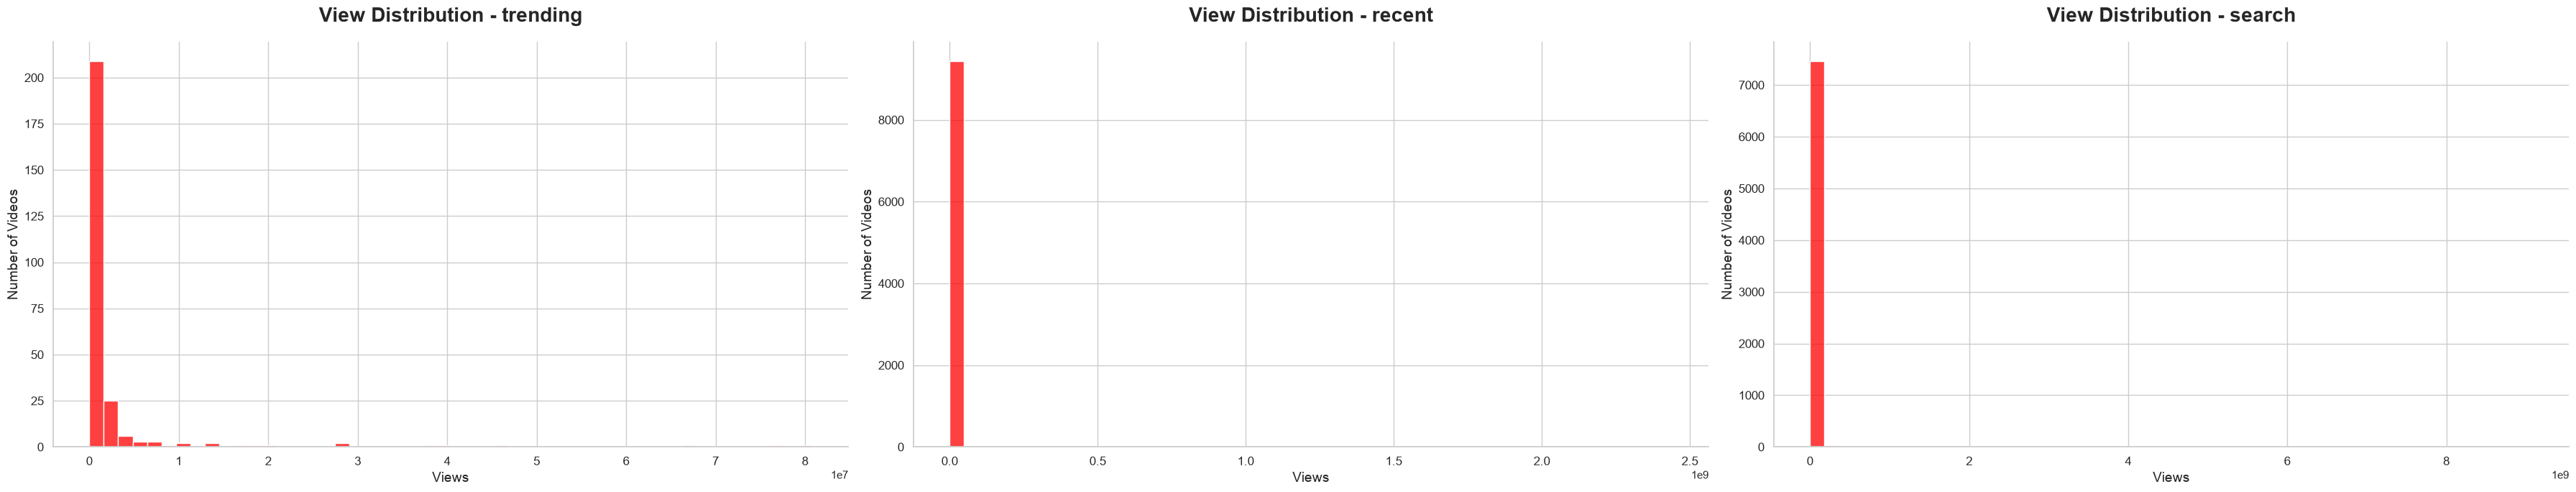

,discovery_source,category_name,count
0,recent,Autos & Vehicles,41
1,recent,Comedy,142
2,recent,Education,505
3,recent,Entertainment,1823
4,recent,Film & Animation,357
5,recent,Gaming,501
6,recent,Howto & Style,136
7,recent,Music,776
8,recent,News & Politics,251
9,recent,Nonprofits,35


In [ ]:


sources = df["discovery_source"].unique()

fig, axes = create_figure(
    nrows=1,
    ncols=len(sources),
    sharey=False
)

# Handles the case where only one subplot exists
if len(sources) == 1:
    axes = [axes]

for ax, source in zip(axes, sources):

    subset = df[df["discovery_source"] == source]

    sns.histplot(
        data=subset,
        x="views",
        bins=50,
        ax=ax,
        color=YOUTUBE_RED
    )

    style_plot(
        ax=ax,
        xlabel="Views",
        ylabel="Number of Videos",
        title=f"View Distribution - {source}"
    )

plt.tight_layout()
plt.show()




In [ ]:
visibility_summary = (
    df.groupby("discovery_source")["views"]
      .agg(
          videos="count",
          median="median",
          mean="mean",
          std="std",
          minimum="min",
          q1=lambda x: x.quantile(.25),
          q3=lambda x: x.quantile(.75),
          maximum="max"
      )
      .round(2)
)

visibility_summary




,videos,median,mean,std,minimum,q1,q3,maximum
discovery_source,,,,,,,,
recent,9461,1412.0,775066.85,2.630762e+07,0,195.00,16811.00,2440969342
search,7526,92810.0,9157981.67,1.359031e+08,0,5597.25,921897.75,9085243852
trending,262,270668.0,2677670.03,9.573144e+06,548,61274.25,1120310.50,80774159


In [ ]:
from scipy.stats import kruskal, chi2_contingency

trend = df[df.discovery_source=="trending"]["views"]
search = df[df.discovery_source=="search"]["views"]
recent = df[df.discovery_source=="recent"]["views"]


kruskal_result = kruskal(
    trend,
    search,
    recent
)

interpret_test(
    "Kruskal-Wallis Test",
    kruskal_result.statistic,
    kruskal_result.pvalue
)

table = pd.crosstab(
    df["category_name"],
    df["discovery_source"]
)
chi2, p, dof, expected = chi2_contingency(table)

interpret_test(
    "Chi-Square Test of Independence",
    chi2,
    p
)

print(f"Degrees of Freedom : {dof}")

Chi2ContingencyResult(statistic=np.float64(1704.339994495644), pvalue=np.float64(0.0), dof=28, expected_freq=array([[1.27799467e+02, 1.01661430e+02, 3.53910372e+00],
       [1.33832918e+02, 1.06460896e+02, 3.70618587e+00],
       [6.49967244e+02, 5.17033451e+02, 1.79993043e+01],
       [1.79303200e+03, 1.42631422e+03, 4.96537770e+01],
       [4.06435214e+02, 3.23309525e+02, 1.12552612e+01],
       [5.47947069e+02, 4.35878834e+02, 1.51740970e+01],
       [1.18475042e+02, 9.42440721e+01, 3.28088585e+00],
       [1.06901786e+03, 8.50378225e+02, 2.96039191e+01],
       [2.64374862e+02, 2.10303902e+02, 7.32123601e+00],
       [4.71706186e+01, 3.75231028e+01, 1.30627862e+00],
       [3.35514737e+03, 2.66893976e+03, 9.29128645e+01],
       [4.77191142e+01, 3.79594179e+01, 1.32146791e+00],
       [3.75719462e+02, 2.98875877e+02, 1.04046611e+01],
       [4.65672735e+02, 3.70431561e+02, 1.28957041e+01],
       [5.86890255e+01, 4.66857209e+01, 1.62525364e+00]]))